#### 4주차

In [5]:
import numpy as np

perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

print (perch_length.shape, perch_weight.shape)


(56,) (56,)


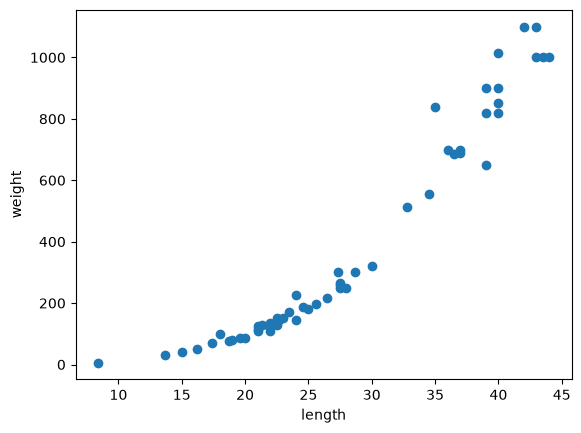

In [6]:
#농어의 산포도
import matplotlib.pyplot as plt

plt.scatter(perch_length, perch_weight)

plt.xlabel('length')
plt.ylabel('weight')

plt.show()

In [7]:
#훈련데이터와 테스트데이터 생성
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target  = train_test_split(perch_length, perch_weight,random_state=42)
#1차원 -> 2차원
train_input = train_input.reshape(-1,1)
test_input = test_input.reshape(-1, 1)
print(train_input.shape, test_input.shape)

(42, 1) (14, 1)


In [ ]:
#k최근접 이웃 회귀
from sklearn.neighbors import KNeighborsRegressor
knr = KNeighborsRegressor()
knr.fit(train_input, train_target)
print(knr.score(train_input, train_target))  #훈련데이터의 점수
print(knr.score(test_input, test_target))   #테스트데이터의 점수

0.9698823289099254
0.992809406101064


In [ ]:
from sklearn.metrics import mean_absolute_error
#테스트데이터에 대한 예측무게
pred = knr.predict(test_input)
pred_target = np.column_stack((pred, test_target)) #예측값과 타겟값을 나란히 출력
print(pred_target)

#테스트 데이터에 대한 평균 절대 오차 구하기
mae = mean_absolute_error(test_target, pred) #타겟과 예측값
print(mae)

In [ ]:
#과소적합 : 훈련데이터 점수 < 테스트데이터 점수 (현재상황)
#과대적합 : 훈련데이터 점수 > 테스트데이터 점수

#이웃의 수를 5에서 3으로 줄여서 해결하기
#이웃의 수가 많아지면 모든 데이터의 평균값에 가까워지므로 과소적합이 발생
#이웃의 수가 적어지면 국소적인 데이터에 민감하게 반응하므로 과대적합이 발생

![k-최근접 이웃 회귀](images/)

In [18]:
knr.neighbors = 3 #5->3
knr.fit(train_input, train_target)
print(knr.score(train_input, train_target))  #훈련데이터의 점수
print(knr.score(test_input, test_target))   #테스트데이터의 점수    


0.9698823289099254
0.992809406101064


In [ ]:
#이웃의 수를 3, 5, 10, 42로 바꾸어 훈련데이터와 테스트데이터의 점수를 확인해보세요.
for n in [3, 5, 10, 42]:
    knr.n_neighbors = n
    knr.fit(train_input, train_target)
    pred = knr.predict(test_input)
    train_score = knr.score(train_input, train_target)
    test_score = knr.score(test_input, test_target)

#훈련데이터, 테스트테이터, 예측값을 산포도로 확인
plt.scatter(train_input, train_target, label='train')
plt.scatter(test_input, test_target, label='test')
plt.scatter(test_input, pred, label = 'prediction (n={neighbors})'.format(n))
plt.legend()
plt.show()

###코드 복붙하기



In [ ]:
#길이가 50인 농어의 무게예측
sample = np.array([[50]])
knr.n_neighbors = 3
knr.fit(train_input, train_target)
pred = knr.predict(sample)
plt